# Fase 2 · Notebook 02 — Modelos de referencia

Proyecto de aula de Inteligencia Artificial · Grupo 04
**Predicción de reingresos hospitalarios a 30 días en pacientes con diabetes**

---

Este notebook entrena los **dos primeros modelos** y, sobre todo, deja demostrado **por qué la
exactitud no sirve** en este problema.

| Modelo | Para qué está |
|---|---|
| **Clasificador mayoritario** | Siempre responde "no reingresa". Es el piso: si un modelo no le gana, no aporta nada. |
| **Regresión logística** | Línea base real, interpretable. Es el modelo contra el que hay que comparar el Gradient Boosting. |
| **Regresión logística balanceada** | La misma, pero dándole más peso a la clase minoritaria. |

> **Todo se evalúa en VALIDACIÓN.** El conjunto de prueba no se toca: se reserva para una única
> evaluación final, con el flujo ya congelado.

## 1. Librerías y datos

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             precision_recall_curve, roc_curve)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 150)

BASE      = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = BASE / "data" / "processed"
FIGURAS   = BASE / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)
print("Proyecto:", BASE)

Proyecto: C:\Users\ASUS\Documents\UPC\proyecto-reingresos


In [2]:
df   = pd.read_csv(PROCESSED / "cohorte_procesada.csv", low_memory=False)
cols = json.loads((PROCESSED / "columnas.json").read_text(encoding="utf-8"))
NUM, CAT = cols["numericas"], cols["categoricas"]

# Los codigos administrativos se leen del CSV como enteros; hay que devolverlos a texto
df[CAT] = df[CAT].astype(str)

es_train = df.conjunto == "entrenamiento"
es_val   = df.conjunto == "validacion"

X_tr, y_tr = df.loc[es_train, NUM + CAT], df.loc[es_train, "y"]
X_va, y_va = df.loc[es_val,   NUM + CAT], df.loc[es_val,   "y"]

PREVALENCIA = y_va.mean()

print(f"Entrenamiento : {X_tr.shape[0]:>6,} filas x {X_tr.shape[1]} columnas")
print(f"Validacion    : {X_va.shape[0]:>6,} filas")
print(f"\nPrevalencia en validacion: {100*PREVALENCIA:.2f} %  ({y_va.sum():,} reingresos de {len(y_va):,})")

Entrenamiento : 59,605 filas x 50 columnas
Validacion    : 19,868 filas

Prevalencia en validacion: 11.39 %  (2,262 reingresos de 19,868)


## 2. El pipeline de preprocesamiento

Un **pipeline** es una cadena de pasos que se ejecutan siempre en el mismo orden. Es importante
por una razón concreta: **los pasos se ajustan solo con los datos de entrenamiento**.

Por ejemplo, el escalado necesita la media y la desviación de cada variable. Si se calcularan
sobre todos los datos, información de validación y prueba se filtraría al entrenamiento. Eso se
llama **fuga de información** (*data leakage*) y hace que los resultados salgan mejor de lo que
realmente son.

Dentro del pipeline, cada tipo de columna recibe un trato distinto:

| Tipo | Paso 1 | Paso 2 |
|---|---|---|
| **Numéricas** (17) | rellenar ausentes con la **mediana** | **escalar** a media 0 y desviación 1 |
| **Categóricas** (33) | rellenar ausentes con la categoría `"Ausente"` | **one-hot**: una columna por categoría |

**¿Por qué la mediana y no el promedio?** Porque hay valores extremos (hasta 81 medicamentos,
21 ingresos previos). El promedio se deja arrastrar por ellos; la mediana no.

**¿Por qué escalar?** La regresión logística compara los pesos de las variables. Sin escalar,
`num_lab_procedures` (hasta 132) pesaría artificialmente más que `number_diagnoses` (hasta 16),
solo porque sus números son más grandes.

**`min_frequency=20`** agrupa en una sola categoría `infrequent` todos los valores que aparecen
menos de 20 veces, para no generar columnas casi vacías.

In [3]:
preprocesador = ColumnTransformer([
    ("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ]), NUM),
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="Ausente")),
        ("onehot",  OneHotEncoder(handle_unknown="ignore", min_frequency=20,
                                  sparse_output=True)),
    ]), CAT),
])

preprocesador.fit(X_tr)
n_columnas = preprocesador.transform(X_tr).shape[1]
print(f"Columnas antes del preprocesamiento : {X_tr.shape[1]}")
print(f"Columnas despues (tras el one-hot)  : {n_columnas}")

Columnas antes del preprocesamiento : 50
Columnas despues (tras el one-hot)  : 200


## 3. Función de evaluación

Se calculan siete medidas para cada modelo. Vale la pena entender qué dice cada una:

| Medida | Qué responde | Ojo |
|---|---|---|
| **Exactitud** | ¿qué porcentaje acertó en total? | **Engaña con clases desbalanceadas** |
| **AP** (*Average Precision*) | ¿qué tan bien ordena los casos por riesgo? | **Métrica principal.** Su referencia es la prevalencia (0,1139) |
| **ROC-AUC** | ¿un positivo al azar tiene mayor puntaje que un negativo al azar? | 0,5 = azar · 1,0 = perfecto |
| **Precisión** | de las alertas que dio, ¿cuántas eran reingresos? | |
| **Recall** (sensibilidad) | de los reingresos reales, ¿cuántos detectó? | **Lo que más importa aquí** |
| **F1** | equilibrio entre precisión y recall | |
| **Matriz de confusión** | VP, FN, FP, VN | Muestra los errores por separado |

> **AP y ROC-AUC no dependen del umbral**: miden qué tan bien el modelo *ordena* los casos.
> Precisión, recall y F1 **sí** dependen del umbral, que aquí se deja provisionalmente en 0,50.

In [4]:
resultados = []
curvas = {}

def evaluar(nombre, modelo):
    """Entrena el modelo, lo evalua en validacion y guarda sus metricas."""
    t0 = time.time()
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    pipe.fit(X_tr, y_tr)

    prob = pipe.predict_proba(X_va)[:, 1]      # probabilidad estimada de reingreso
    pred = (prob >= 0.50).astype(int)          # decision con umbral 0,50
    vn, fp, fn, vp = confusion_matrix(y_va, pred).ravel()

    resultados.append({
        "modelo": nombre,
        "exactitud": accuracy_score(y_va, pred),
        "AP": average_precision_score(y_va, prob),
        "ROC_AUC": roc_auc_score(y_va, prob),
        "precision": precision_score(y_va, pred, zero_division=0),
        "recall": recall_score(y_va, pred, zero_division=0),
        "F1": f1_score(y_va, pred, zero_division=0),
        "VP": vp, "FN": fn, "FP": fp, "VN": vn,
        "segundos": round(time.time() - t0, 1),
    })
    curvas[nombre] = prob
    print(f"{nombre}: entrenado en {time.time()-t0:.1f} s")
    return pipe

print("Funcion lista.")

Funcion lista.


## 4. Modelo 1 — Clasificador mayoritario

No aprende nada: **siempre responde la clase más frecuente**, que aquí es "no reingresa".

Está en el proyecto por una razón: es el **piso**. Cualquier modelo que no le gane claramente
no está aportando información.

In [5]:
pipe_mayoritario = evaluar("Mayoritario", DummyClassifier(strategy="most_frequent"))
r = resultados[-1]
print(f"\n   Exactitud : {100*r['exactitud']:.2f} %")
print(f"   Recall    : {100*r['recall']:.2f} %")
print(f"   Reingresos detectados: {r['VP']} de {r['VP']+r['FN']:,}")

Mayoritario: entrenado en 1.6 s

   Exactitud : 88.61 %
   Recall    : 0.00 %
   Reingresos detectados: 0 de 2,262


### 🚨 Aquí está el problema del proyecto, en dos números

```
Exactitud : 88,61 %     ->  suena excelente
Recall    :  0,00 %     ->  no detecto NI UN SOLO reingreso
```

Un modelo que **no hace absolutamente nada** acierta casi el 89 % de las veces, simplemente
porque casi nadie reingresa. Si el criterio de selección fuera la exactitud, este modelo
inútil ganaría.

**Por eso la métrica principal del proyecto es la Average Precision**, cuyo valor de referencia
es la prevalencia (0,1139). El mayoritario obtiene exactamente eso: no supera el azar.

## 5. Modelo 2 — Regresión logística

Es un modelo lineal: calcula una suma ponderada de las características y la pasa por la función
**sigmoide**, que convierte el resultado en una probabilidad entre 0 y 1.

> Es exactamente la misma idea de una neurona con activación `logsig`: suma ponderada → sigmoide
> → probabilidad.

Se usa como línea base porque es **rápida, estable e interpretable**: cada coeficiente dice en
qué dirección empuja cada variable.

In [6]:
pipe_logistica = evaluar("Reg. logistica", LogisticRegression(max_iter=2000, n_jobs=-1))
r = resultados[-1]
print(f"\n   Exactitud : {100*r['exactitud']:.2f} %")
print(f"   AP        : {r['AP']:.4f}   (referencia = prevalencia = {PREVALENCIA:.4f})")
print(f"   ROC-AUC   : {r['ROC_AUC']:.4f}")
print(f"   Recall    : {100*r['recall']:.2f} %  ->  detecto {r['VP']} de {r['VP']+r['FN']:,} reingresos")

C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Reg. logistica: entrenado en 2.5 s

   Exactitud : 88.63 %
   AP        : 0.2136   (referencia = prevalencia = 0.1139)
   ROC-AUC   : 0.6540
   Recall    : 1.50 %  ->  detecto 34 de 2,262 reingresos


### Lo que acaba de pasar es muy informativo

La exactitud subió de 88,61 % a 88,63 %: **casi nada**. Pero la AP pasó de 0,1139 a 0,2136, y
el ROC-AUC de 0,50 a 0,654. **El modelo sí aprendió algo real** — la exactitud simplemente no
es capaz de verlo.

Y aun así, **con umbral 0,50 detecta apenas el 1,5 % de los reingresos**. No porque el modelo
sea malo, sino porque **0,50 es un umbral demasiado exigente** para una clase que solo ocurre
el 11 % de las veces: casi ningún caso alcanza una probabilidad tan alta.

**El umbral es una decisión aparte del modelo.** Se verá en la sección 7.

## 6. Modelo 3 — Regresión logística balanceada

`class_weight="balanced"` le dice al modelo que **los errores sobre la clase minoritaria cuestan
más**. Como hay 7,8 negativos por cada positivo, cada positivo pesa 7,8 veces más durante el
entrenamiento.

Es una de las formas estándar de tratar el desbalance.

In [7]:
pipe_balanceada = evaluar("Reg. logistica balanceada",
                          LogisticRegression(max_iter=2000, class_weight="balanced", n_jobs=-1))
r = resultados[-1]
print(f"\n   Exactitud : {100*r['exactitud']:.2f} %   <- BAJO mucho")
print(f"   Recall    : {100*r['recall']:.2f} %   <- SUBIO mucho")
print(f"   AP        : {r['AP']:.4f}   <- practicamente igual que sin balancear")

C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Reg. logistica balanceada: entrenado en 3.0 s

   Exactitud : 66.03 %   <- BAJO mucho
   Recall    : 55.08 %   <- SUBIO mucho
   AP        : 0.2131   <- practicamente igual que sin balancear


## 7. Comparación de los tres modelos

In [8]:
tabla = pd.DataFrame(resultados).set_index("modelo")
display(tabla[["exactitud", "AP", "ROC_AUC", "precision", "recall", "F1"]].round(4))
print()
display(tabla[["VP", "FN", "FP", "VN", "segundos"]])
print(f"\nReferencia: AP de un modelo al azar = prevalencia = {PREVALENCIA:.4f}")
print(f"Mejor AP: {tabla.AP.idxmax()} con {tabla.AP.max():.4f} "
      f"= {tabla.AP.max()/PREVALENCIA:.2f} veces la prevalencia")

,exactitud,AP,ROC_AUC,precision,recall,F1
modelo,,,,,,
Mayoritario,0.8861,0.1139,0.5000,0.0000,0.0000,0.0000
Reg. logistica,0.8863,0.2136,0.6540,0.5312,0.0150,0.0292
Reg. logistica balanceada,0.6603,0.2131,0.6552,0.1785,0.5508,0.2697


,VP,FN,FP,VN,segundos
modelo,,,,,
Mayoritario,0,2262,0,17606,1.6
Reg. logistica,34,2228,30,17576,2.5
Reg. logistica balanceada,1246,1016,5733,11873,3.0



Referencia: AP de un modelo al azar = prevalencia = 0.1139
Mejor AP: Reg. logistica con 0.2136 = 1.88 veces la prevalencia


### 🔑 La conclusión más importante de este notebook

Mira las dos regresiones logísticas:

| | Exactitud | Recall | **AP** | **ROC-AUC** |
|---|---|---|---|---|
| Sin balancear | 88,63 % | 1,50 % | **0,2136** | **0,6540** |
| Balanceada | 66,03 % | 55,08 % | **0,2131** | **0,6552** |

**La AP y el ROC-AUC son prácticamente idénticos.** Eso significa que las dos versiones
**ordenan los casos exactamente igual de bien**. Balancear no hizo al modelo más inteligente:
solo **movió el umbral de decisión** por debajo del capó.

Es una distinción que conviene tener clara para la sustentación:

- **Qué tan bien ordena el modelo** → lo miden AP y ROC-AUC. Es una propiedad del modelo.
- **Cuántos detecta** → depende del umbral. Es una decisión que se toma *después*, según lo que
  cueste cada tipo de error.

Se puede obtener el mismo recall sin balancear, simplemente bajando el umbral. Es lo que se ve
a continuación.

## 8. El efecto del umbral

Se recorre el umbral desde 0,05 hasta 0,50 con la regresión logística **sin balancear**, para
ver cómo cambian precisión y recall.

In [9]:
prob_log = curvas["Reg. logistica"]
filas = []
for u in [0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (prob_log >= u).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_va, pred).ravel()
    filas.append({
        "umbral": u,
        "alertas": int(pred.sum()),
        "% de la poblacion": round(100 * pred.mean(), 1),
        "recall": round(recall_score(y_va, pred, zero_division=0), 4),
        "precision": round(precision_score(y_va, pred, zero_division=0), 4),
        "VP": vp, "FN": fn, "FP": fp,
    })
display(pd.DataFrame(filas).set_index("umbral"))

,alertas,% de la poblacion,recall,precision,VP,FN,FP
umbral,,,,,,,
0.05,18755,94.4,0.9761,0.1177,2208,54,16547
0.08,12592,63.4,0.7896,0.1418,1786,476,10806
0.10,8870,44.6,0.6366,0.1623,1440,822,7430
0.12,6275,31.6,0.5111,0.1842,1156,1106,5119
0.15,3870,19.5,0.3656,0.2137,827,1435,3043
0.20,1790,9.0,0.2095,0.2648,474,1788,1316
0.25,870,4.4,0.1198,0.3115,271,1991,599
0.30,486,2.4,0.0743,0.3457,168,2094,318
0.40,172,0.9,0.0354,0.4651,80,2182,92


**Así se lee esta tabla, en términos del hospital:**

El umbral define **a cuántos pacientes se les hace seguimiento reforzado al salir**. Bajarlo
significa alertar a más gente: se detectan más reingresos (sube el recall), pero una proporción
mayor de esas alertas resulta ser falsa (baja la precisión).

No existe un umbral "correcto" en abstracto: **depende de cuántos recursos hay para hacer
seguimiento y de cuánto cuesta dejar pasar un reingreso**. La Fase 1 propuso explorar un punto
con recall ≥ 0,60 y precisión ≥ 0,20.

## 9. Curvas

**Curva precisión-recall.** Es la que más importa con clases desbalanceadas. La línea punteada
es la prevalencia: el nivel de un modelo que responde al azar. **El área bajo esta curva es la AP.**

**Curva ROC.** Enfrenta la tasa de verdaderos positivos contra la de falsos positivos. La
diagonal es el azar. **El área bajo esta curva es el ROC-AUC.**

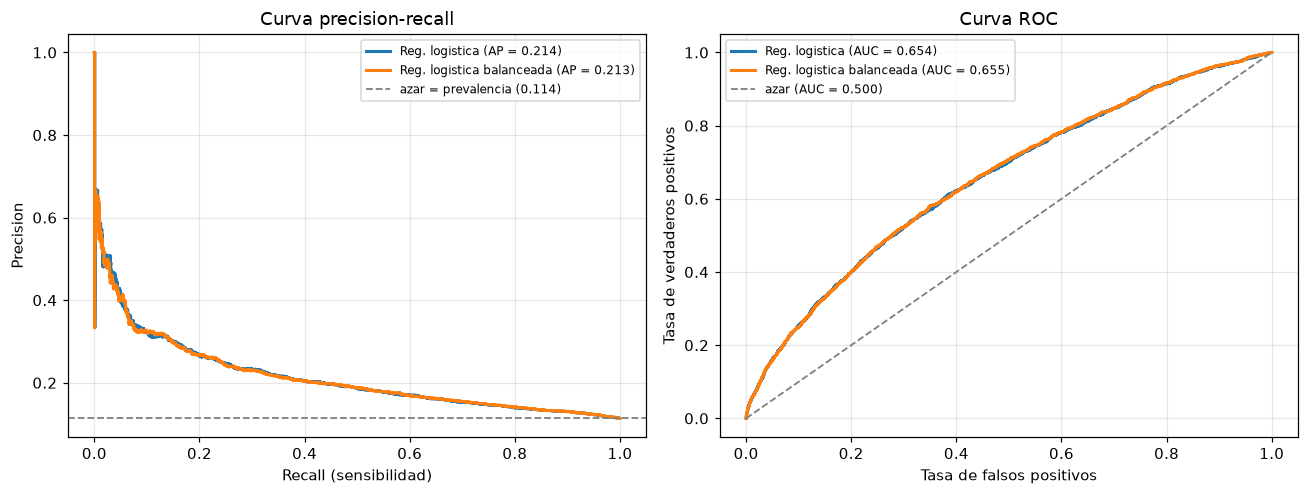

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

for nombre, prob in curvas.items():
    if nombre == "Mayoritario":
        continue
    pr, rc, _ = precision_recall_curve(y_va, prob)
    ax1.plot(rc, pr, lw=2, label=f"{nombre} (AP = {average_precision_score(y_va, prob):.3f})")
    fpr, tpr, _ = roc_curve(y_va, prob)
    ax2.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_va, prob):.3f})")

ax1.axhline(PREVALENCIA, ls="--", c="gray", lw=1.2,
            label=f"azar = prevalencia ({PREVALENCIA:.3f})")
ax1.set_xlabel("Recall (sensibilidad)"); ax1.set_ylabel("Precision")
ax1.set_title("Curva precision-recall"); ax1.legend(fontsize=8); ax1.grid(alpha=.3)

ax2.plot([0, 1], [0, 1], ls="--", c="gray", lw=1.2, label="azar (AUC = 0.500)")
ax2.set_xlabel("Tasa de falsos positivos"); ax2.set_ylabel("Tasa de verdaderos positivos")
ax2.set_title("Curva ROC"); ax2.legend(fontsize=8); ax2.grid(alpha=.3)

plt.tight_layout()
plt.savefig(FIGURAS / "02_curvas_baseline.png", bbox_inches="tight", dpi=150)
plt.show()

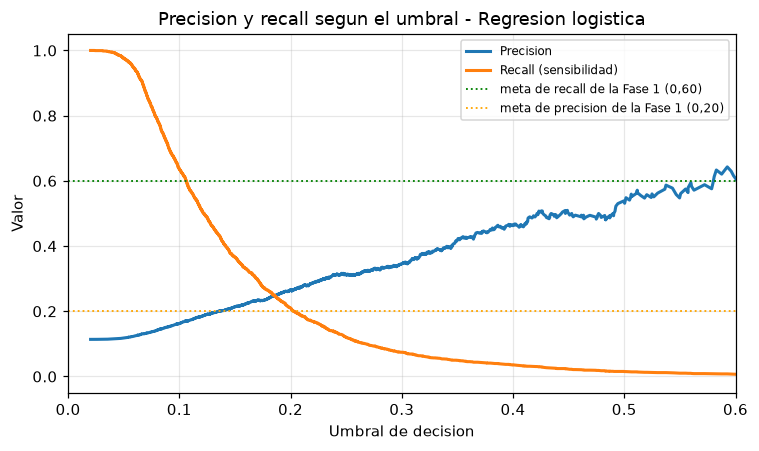

In [11]:
# Precision y recall en funcion del umbral
fig, ax = plt.subplots(figsize=(7, 4.2))
pr, rc, umb = precision_recall_curve(y_va, prob_log)
ax.plot(umb, pr[:-1], lw=2, label="Precision")
ax.plot(umb, rc[:-1], lw=2, label="Recall (sensibilidad)")
ax.axhline(0.60, ls=":", c="green", lw=1.2, label="meta de recall de la Fase 1 (0,60)")
ax.axhline(0.20, ls=":", c="orange", lw=1.2, label="meta de precision de la Fase 1 (0,20)")
ax.set_xlim(0, 0.6)
ax.set_xlabel("Umbral de decision"); ax.set_ylabel("Valor")
ax.set_title("Precision y recall segun el umbral - Regresion logistica")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURAS / "02_umbral.png", bbox_inches="tight", dpi=150)
plt.show()

## 10. Guardar los resultados

In [12]:
REPORTES = BASE / "reports"
tabla.round(6).to_csv(REPORTES / "metricas_02_baseline.csv")
np.save(PROCESSED / "prob_val_logistica.npy", prob_log)

print("Guardado:")
print("  ", REPORTES / "metricas_02_baseline.csv")
print("  ", FIGURAS  / "02_curvas_baseline.png")
print("  ", FIGURAS  / "02_umbral.png")

Guardado:
   C:\Users\ASUS\Documents\UPC\proyecto-reingresos\reports\metricas_02_baseline.csv
   C:\Users\ASUS\Documents\UPC\proyecto-reingresos\reports\figures\02_curvas_baseline.png
   C:\Users\ASUS\Documents\UPC\proyecto-reingresos\reports\figures\02_umbral.png


---

## Resumen

| Modelo | Exactitud | AP | ROC-AUC | Recall |
|---|---|---|---|---|
| Mayoritario | 88,61 % | 0,1139 | 0,500 | 0,00 % |
| Regresión logística | 88,63 % | **0,2136** | **0,654** | 1,50 % |
| Regresión logística balanceada | 66,03 % | 0,2131 | 0,655 | 55,08 % |

### Contra las metas propuestas en la Fase 1

| Meta de la Fase 1 | Obtenido | |
|---|---|---|
| AP ≥ 1,5 × prevalencia (≥ 0,171) | **0,2136 = 1,88 ×** | ✅ cumplida |
| ROC-AUC ≥ 0,65 | **0,654** | ✅ cumplida (por poco) |
| Recall ≥ 0,60 con precisión ≥ 0,20 | pendiente de ajustar el umbral | ⏳ |

### Lo que queda demostrado

1. **La exactitud no sirve como criterio** en este problema: un modelo que no hace nada obtiene 88,61 %.
2. **La regresión logística ya supera el azar**: su AP es 1,88 veces la prevalencia.
3. **Balancear no mejora el ordenamiento**, solo desplaza el umbral. AP y ROC-AUC quedan iguales.
4. **El umbral es una decisión separada del modelo** y debe elegirse según el costo de cada error.

**Siguiente:** `03_hiperparametros.ipynb` — Gradient Boosting y ajuste de hiperparámetros.